In [3]:
# =============================================================================
# Librerías
# =============================================================================
import numpy as np                      # arreglos y operaciones numericas
import matplotlib.pyplot as plt         # graficas
from scipy.stats import poisson, gamma, norm  # distribuciones de probabilidad
from math import exp, factorial         # para la suma "a mano" de la Poisson

In [4]:
# =============================================================================
# Funciones del modelo
# =============================================================================
def prob_suficiente(n, lam, t, m=1):
    '''P(N(t) <= n): probabilidad de que n repuestos alcancen durante [0, t]
        Se calcula con la formula explicita de la Poisson:
            sum_{k=0}^{n} e^{-mu} mu^k / k!,   con mu = m * lambda * t
    '''
    mu = m * lam * t                            # media de fallas en [0, t]
    return sum(exp(-mu) * mu**k / factorial(k)  # termino k de la Poisson
               for k in range(n + 1))           # k = 0, 1, ..., n

def stock_minimo(lam, t, alpha, m=1):
    '''Menor n tal que P(N(t) <= n) >= 1 - alpha (busqueda secuencial)'''
    n = 0                                       # empezamos con 0 repuestos
    while prob_suficiente(n, lam, t, m) < 1 - alpha:
        n += 1                                  # mientras no alcance la confianza agregamos un repuesto mas
    return n                                    # primera n que cumple

def stock_scipy(lam, t, alpha, m=1):
    '''Mismo resultado usando el cuantil (ppf) de la Poisson de SciPy'''
    return int(poisson.ppf(1 - alpha, m * lam * t))    # cuantil 1-alpha de Poisson(m * lam * t)


def stock_normal(lam, t, alpha, m=1):
    '''Aproximacion normal: n ~ ceil(mu + z_{1-alpha} * sqrt(mu))'''
    mu = m * lam * t                            # media (= varianza) de la Poisson
    z = norm.ppf(1 - alpha)                     # cuantil normal estandar (1.645 si alpha=0.05)
    return int(np.ceil(mu + z * np.sqrt(mu)))   # redondeamos hacia arriba

In [5]:
# =============================================================================
# Pregunta 2: analisis numerico con alpha=0.05, lambda=0.02, t=1000
# =============================================================================
alpha, lam, t = 0.05, 0.02, 1000        # parametros del enunciado
mu = lam * t                            # numero esperado de fallas = 20

print("=== Pregunta 2 ===")
print(f"mu = lambda*t = {mu}")

# Tabla de la probabilidad acumulada alrededor del valor buscado
for n in range(20, 31):                         # revisamos n = 20..30
    p = prob_suficiente(n, lam, t)              # P(N(1000) <= n)
    marca = "  <-- cumple" if p >= 1 - alpha else ""   # señalamos si ya pasa 0.95
    print(f"n = {n:2d}   P(N<=n) = {p:.4f}{marca}")

n_opt = stock_minimo(lam, t, alpha)             # busqueda exacta
print(f"Stock minimo (busqueda exacta) : {n_opt}")
print(f"Stock minimo (scipy ppf)       : {stock_scipy(lam, t, alpha)}")
print(f"Stock (aprox. normal)          : {stock_normal(lam, t, alpha)}")

# Comprobacion con la forma Erlang/Gamma: P(S_{n+1} > t) con S_{n+1} ~ Gamma(n+1, lambda)
p_gamma = gamma.sf(t, a=n_opt + 1, scale=1 / lam)      # sf = 1 - cdf = P(S > t)
print(f"Verificacion Erlang P(S_(n+1) > t) = {p_gamma:.4f}")

# Validacion por simulacion Monte Carlo 🫡
rng = np.random.default_rng(42)                 # generador con semilla (con el fin de replicar)
R = 100_000                                     # numero de replicas
vidas = rng.exponential(1 / lam, size=(R, n_opt + 1))  # n+1 vidas por replica (instalado + stock)
exito = vidas.sum(axis=1) > t                   # el sistema llega a t si la suma supera t
print(f"Simulacion Monte Carlo: {exito.mean():.4f}")

# Caso general: m componentes en serie (tabla ilustrativa)
print("\nm componentes en serie (alpha=0.05, lambda=0.02, t=1000):")
for m in [1, 2, 3, 5]:
    print(f"m = {m}:  stock = {stock_minimo(lam, t, alpha, m)}")

=== Pregunta 2 ===
mu = lambda*t = 20.0
n = 20   P(N<=n) = 0.5591
n = 21   P(N<=n) = 0.6437
n = 22   P(N<=n) = 0.7206
n = 23   P(N<=n) = 0.7875
n = 24   P(N<=n) = 0.8432
n = 25   P(N<=n) = 0.8878
n = 26   P(N<=n) = 0.9221
n = 27   P(N<=n) = 0.9475
n = 28   P(N<=n) = 0.9657  <-- cumple
n = 29   P(N<=n) = 0.9782  <-- cumple
n = 30   P(N<=n) = 0.9865  <-- cumple
Stock minimo (busqueda exacta) : 28
Stock minimo (scipy ppf)       : 28
Stock (aprox. normal)          : 28
Verificacion Erlang P(S_(n+1) > t) = 0.9657
Simulacion Monte Carlo: 0.9649

m componentes en serie (alpha=0.05, lambda=0.02, t=1000):
m = 1:  stock = 28
m = 2:  stock = 51
m = 3:  stock = 73
m = 5:  stock = 117



=== Pregunta 3 ===
t =   100  lambda*t =    2.0  stock =    5  colchon =   3.0
t =   250  lambda*t =    5.0  stock =    9  colchon =   4.0
t =   500  lambda*t =   10.0  stock =   15  colchon =   5.0
t =  1000  lambda*t =   20.0  stock =   28  colchon =   8.0
t =  2000  lambda*t =   40.0  stock =   51  colchon =  11.0
t =  3000  lambda*t =   60.0  stock =   73  colchon =  13.0
t =  5000  lambda*t =  100.0  stock =  117  colchon =  17.0


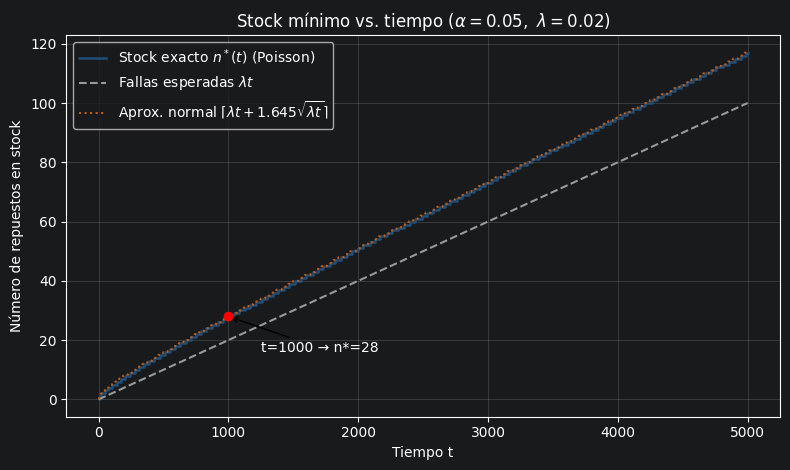

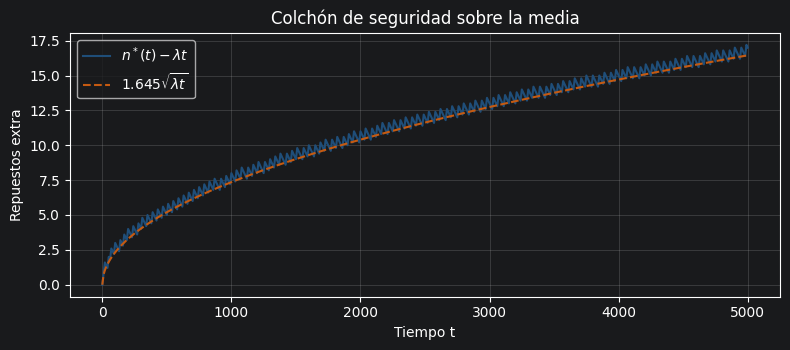

In [6]:
# =============================================================================
# Pregunta 3: variar t y ver como cambia el stock
# =============================================================================
ts = np.arange(0, 5001, 10)                            # tiempos de 0 a 5000 en pasos de 10
stock = [stock_scipy(lam, ti, alpha) for ti in ts]     # stock exacto para cada t
media = lam * ts                                       # fallas esperadas lambda*t
aprox = [stock_normal(lam, ti, alpha) if ti > 0 else 0 for ti in ts]  # aproximacion normal

print("\n=== Pregunta 3 ===")
for ti in [100, 250, 500, 1000, 2000, 3000, 5000]:     # tabla de algunos t
    n_i = stock_scipy(lam, ti, alpha)
    print(f"t = {ti:5d}  lambda*t = {lam*ti:6.1f}  stock = {n_i:4d}  "
          f"colchon = {n_i - lam*ti:5.1f}")

# Grafica principal: stock vs tiempo
fig, ax = plt.subplots(figsize=(8, 4.8))                    # figura y ejes
ax.step(ts, stock, where="post", color="#1f4e79",
        lw=1.8, label=r"Stock exacto $n^*(t)$ (Poisson)")   # funcion escalonada
ax.plot(ts, media, "--", color="#999999",
        label=r"Fallas esperadas $\lambda t$")              # recta de la media
ax.plot(ts, aprox, ":", color="#c55a11", lw=1.5,
        label=r"Aprox. normal $\lceil\lambda t + 1.645\sqrt{\lambda t}\rceil$")
ax.scatter([t], [n_opt], color="red", zorder=5)             # punto de la pregunta 2
ax.annotate(f"t=1000 → n*={n_opt}", (t, n_opt), xytext=(t + 250, n_opt - 12),
            arrowprops=dict(arrowstyle="->"))               # etiqueta del punto
ax.set_xlabel("Tiempo t")
ax.set_ylabel("Número de repuestos en stock")
ax.set_title(r"Stock mínimo vs. tiempo ($\alpha=0.05,\ \lambda=0.02$)")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig("stock_vs_t.png", dpi=200)

# Grafica secundaria: colchon de seguridad n*(t) - lambda*t
fig2, ax2 = plt.subplots(figsize=(8, 3.6))
ax2.plot(ts, np.array(stock) - media, color="#1f4e79", label=r"$n^*(t) - \lambda t$")                   # colchon exacto
ax2.plot(ts, norm.ppf(0.95) * np.sqrt(media), "--", color="#c55a11", label=r"$1.645\sqrt{\lambda t}$")  # colchon teorico
ax2.set_xlabel("Tiempo t")
ax2.set_ylabel("Repuestos extra")
ax2.set_title("Colchón de seguridad sobre la media")
ax2.grid(alpha=0.3)
ax2.legend()
fig2.tight_layout()
fig2.savefig("colchon_vs_t.png", dpi=200)